# Análise complementar: logística do desfecho e peso ao nascer contínuo — São Paulo (capital), 2024
**IPT — Mestrado em Computação Aplicada**

Responde a duas sugestões da professora: uma regressão logística do baixo peso (limite de 2.600 g, comparado com os 2.500 g do estudo) e a comparação do peso em gramas segundo o mês de início do pré-natal. Usa a população do [notebook 03](03_estimacao_ato.ipynb) e não altera o ATO. Execute com a `.venv` do projeto ([requirements.txt](../../requirements.txt)); o notebook não grava arquivos.

| | População | X1 = 1 | X1 = 0 |
|---|---|---|---|
| **P6** (principal, a mesma do 03) | início do pré-natal nos meses 1–6 | meses 1–3 | meses 4–6 |
| **P9** (sensibilidade, "X1 = 0 caso contrário") | início nos meses 1–9 | meses 1–3 | meses 4–9 |

**Previsão, associação e causalidade.** A seção 2 mede **previsão**: quanto as características maternas antecipam o baixo peso em nascimentos que o modelo não viu. A seção 1 mede **associação**: a razão de chances (OR) de X1 entre mães com o mesmo perfil observado. Nenhuma das duas estima **efeito causal**; valores-p pequenos também não.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import scipy
import sklearn
from plotly.subplots import make_subplots
from sklearn.metrics import precision_recall_curve, roc_curve
from IPython.display import Markdown, display

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file() and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.amostra import _criar_views
from src.graficos import (COR_REFERENCIA, COR_T0, COR_T1, COR_TEXTO, FONTE_SINASC_2024, exibir_plotly,
                          fmt_br as fmt, layout_academico)
from src.logistica_desfecho import (MODELOS, PREDITORES_M3, X1, ajustar_modelo, codificar_preditores,
                                    construir_modelo, curva_calibracao, definir_desfechos,
                                    metricas_probabilisticas, prever_fora_da_amostra, razoes_de_chances,
                                    validar_preditores)
from src.peso_continuo import anova_welch, comparar_medias_welch, resumir_peso

PARQUET = raiz / "data" / "processed" / "sinasc_2024.parquet"
MUNICIPIO = "355030"
ESPERADO_P6 = {"n": 114_694, "x1": 104_576, "y2500": 9_850}  # conferido no notebook 03
DESFECHOS = {"< 2.600 g": "Y_2600", "< 2.500 g": "Y_2500"}
assert PARQUET.is_file(), f"Base local ausente: {PARQUET}"
print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__, "| SciPy", scipy.__version__,
      "| scikit-learn", sklearn.__version__)

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6 | SciPy 1.17.1 | scikit-learn 1.8.0


In [2]:
# Mesma projeção SQL e mesma elegibilidade do 03 (gestação única, peso 500–6.000 g, residência na capital),
# sem o filtro de mês, para separar P6, P9 e os registros sem mês válido.
with duckdb.connect() as con:
    _criar_views(con, PARQUET)
    sql_view = con.execute("SELECT sql FROM duckdb_views() WHERE view_name = 'amostra_principal'").fetchone()[0]
    projecao = sql_view[sql_view.index(" AS SELECT ") + 4: sql_view.index(" FROM fase1_base")]
    # CONSPRENAT só descreve o grupo sem mês válido; não entra em nenhum modelo.
    base = con.execute(
        projecao + ", mesprenat_num, peso_num, try_cast(CONSPRENAT AS INTEGER) AS consprenat_num FROM fase1_base"
        " WHERE y_p1 IS NOT NULL AND gravidez_num = 1 AND CAST(CODMUNRES AS VARCHAR) = ?"
        " ORDER BY contador", [MUNICIPIO]).df()

assert base.contador.notna().all() and base.contador.is_unique
mes_valido = base.mesprenat_num.between(1, 9).fillna(False).astype(bool)  # mês nulo (Int32 anulável) fica fora
sem_mes = base[~mes_valido]   # MESPRENAT vazio ou 99 ("ignorado"): só descrito na seção 3
sem_codigo, codigo_99 = int(sem_mes.mesprenat_num.isna().sum()), int(sem_mes.mesprenat_num.eq(99).sum())
zero_consulta = int(sem_mes.consprenat_num.eq(0).sum())
p9 = base[mes_valido].copy()
p6 = p9[p9.mesprenat_num.between(1, 6)].copy()
for dados in (p6, p9):
    dados[X1] = dados.mesprenat_num.le(3).astype(int)
    dados[["Y_2500", "Y_2600"]] = definir_desfechos(dados.peso_num).to_numpy()
    assert dados.tratamento.eq(dados[X1]).all()
assert {"n": len(p6), "x1": int(p6[X1].sum()), "y2500": int(p6.Y_2500.sum())} == ESPERADO_P6
x_p6, x_p9 = codificar_preditores(p6), codificar_preditores(p9)
validar_preditores(x_p6.columns)
print(f"P6: {fmt(len(p6))} nascimentos | X1=1 {fmt(p6[X1].sum())} | X1=0 {fmt((p6[X1] == 0).sum())} | "
      f"< 2.500 g {fmt(p6.Y_2500.sum())} | < 2.600 g {fmt(p6.Y_2600.sum())}")
print(f"P9: {fmt(len(p9))} nascimentos (P6 + {fmt(len(p9) - len(p6))} com início nos meses 7–9) | "
      f"sem mês válido: {fmt(len(sem_mes))} ({fmt(sem_codigo)} sem código e {fmt(codigo_99)} com o código 99, "
      f"\"ignorado\"; {fmt(zero_consulta)} com zero consulta de pré-natal registrada)")
print("Preditores do M3:", ", ".join(x_p6.columns))

P6: 114.694 nascimentos | X1=1 104.576 | X1=0 10.118 | < 2.500 g 9.850 | < 2.600 g 12.962
P9: 116.429 nascimentos (P6 + 1.735 com início nos meses 7–9) | sem mês válido: 993 (889 sem código e 104 com o código 99, "ignorado"; 910 com zero consulta de pré-natal registrada)
Preditores do M3: X1_INICIO_1_3, IDADEMAE_NUM, IDADEMAE_QUAD, ESCOLARIDADE_MAE, RACA_COR_MAE, PARIDADE_CAT, PERDAS_FETAIS_CAT


## 1. Associação: razão de chances ajustada

O **M3** é o modelo proposto pela professora: X1, idade (com termo quadrático, porque o risco cresce nos extremos), escolaridade, raça/cor, paridade e perdas fetais anteriores. São as covariáveis do escore do 03, todas anteriores à gestação; nada do parto ou da assistência entra.

**Codificação de níveis raros.** A regra foi fixada antes do ajuste, pelo número de nascimentos, sem olhar associações; ela evita estimativas infinitas na logística sem penalização:
- **Escolaridade:** "sem escolaridade" (33 nascimentos, 2 com peso < 2.500 g) foi agrupada com "fundamental I" (692). A OR do grupo é, na prática, a de fundamental I (95% dos registros) e nada informa sobre mães sem escolaridade.
- **Ignorados:** os 94 registros com escolaridade, raça/cor ou perdas fetais "ignorado" receberam a categoria de referência, que é também a mais frequente. É uma imputação pela moda: trata esses valores como observados, sem incerteza, e descarta a informação de ausência, embora esse grupo tenha mais baixo peso (12,8%).
- **Casos completos:** a sensibilidade na tabela abaixo exclui esses 94 registros; a especificação principal não muda.

,Casos na P6,Risco X1=1 (%),Risco X1=0 (%),OR bruta de X1,"OR ajustada (M3, P6)","OR ajustada (M3, P9)","OR ajustada (M3, P6, casos completos)"
Desfecho,,,,,,,
< 2.600 g,"12.962 (11,30%)","11,10","13,39","0,81 (0,76 a 0,86)","0,83 (0,78 a 0,88)","0,85 (0,80 a 0,90)","0,83 (0,78 a 0,88)"
< 2.500 g,"9.850 (8,59%)","8,41","10,41","0,79 (0,74 a 0,85)","0,81 (0,76 a 0,87)","0,84 (0,78 a 0,89)","0,82 (0,76 a 0,87)"


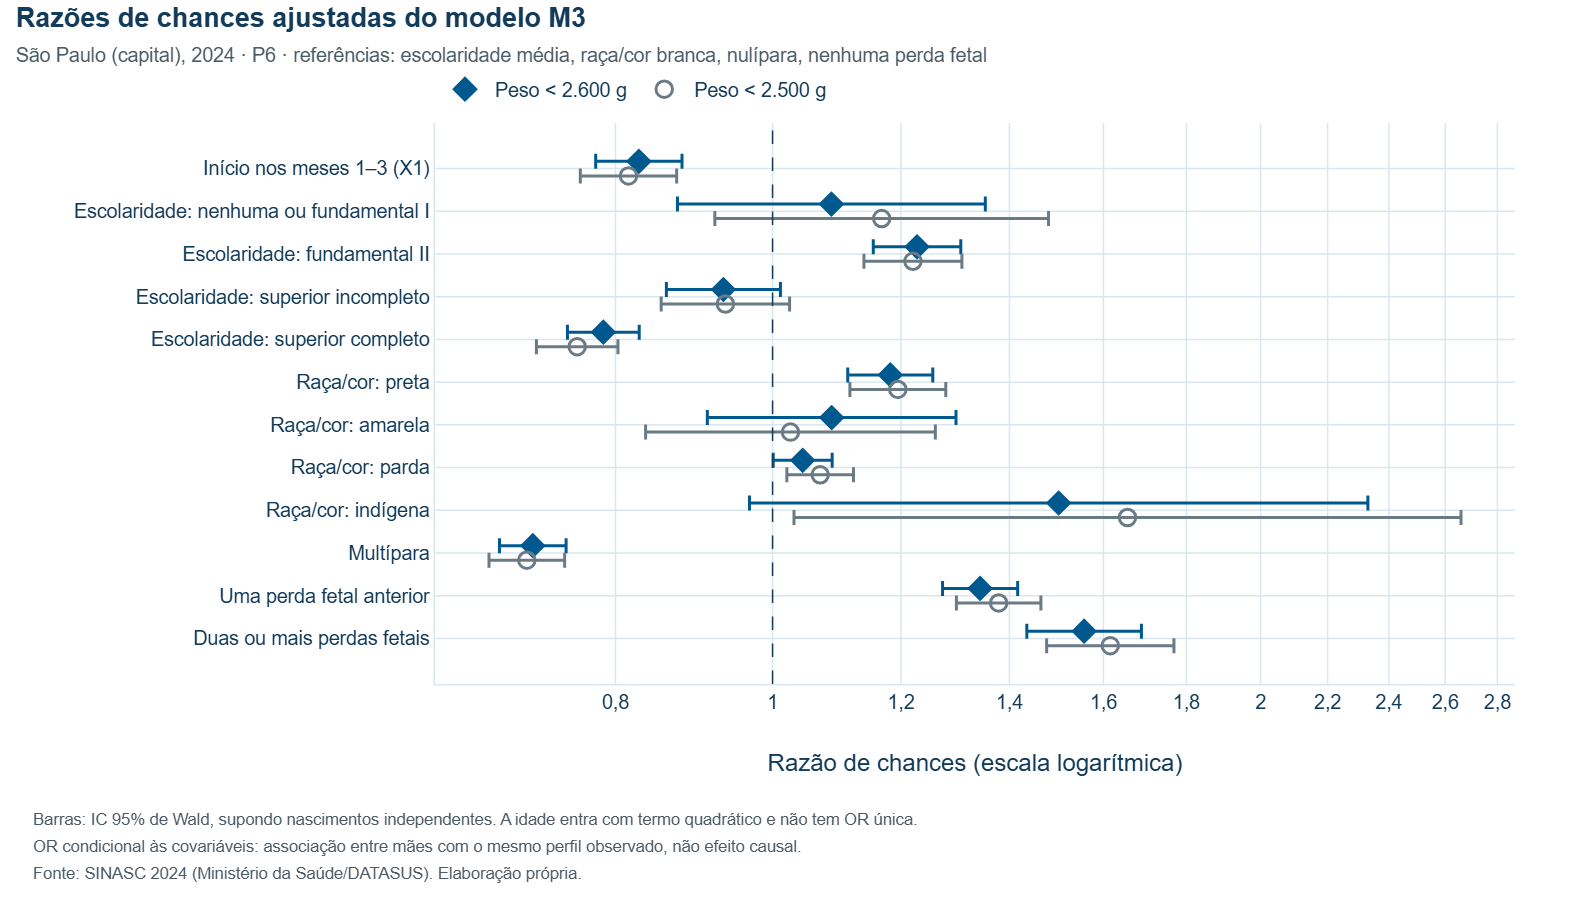

Entre mães com o mesmo perfil observado, o início nos meses 1–3 se associa a chances menores de peso < 2.600 g (OR 0,83; IC 95% 0,78 a 0,88) e a chances menores de peso < 2.500 g (OR 0,81; IC 95% 0,76 a 0,87). Sem os 94 registros com características ignoradas (casos completos), as OR ficam em 0,83 e 0,82; na P9 (X1 = 0 inclui os meses 7–9), a OR para < 2.600 g é 0,85 (IC 95% 0,80 a 0,90), mas esse grupo só reúne gestações que chegaram ao 7º mês, o que pode deslocar X1 = 0 para gestações mais longas e mais pesadas (seleção temporal). A OR é uma associação condicional na população inteira: não estima efeito causal nem equivale à diferença de riscos do ATO no notebook 03.

In [3]:
ROTULOS = {
    X1: "Início nos meses 1–3 (X1)",
    "ESCOLARIDADE_MAE_0-1": "Escolaridade: nenhuma ou fundamental I", "ESCOLARIDADE_MAE_2": "Escolaridade: fundamental II",
    "ESCOLARIDADE_MAE_4": "Escolaridade: superior incompleto", "ESCOLARIDADE_MAE_5": "Escolaridade: superior completo",
    "RACA_COR_MAE_2": "Raça/cor: preta", "RACA_COR_MAE_3": "Raça/cor: amarela", "RACA_COR_MAE_4": "Raça/cor: parda",
    "RACA_COR_MAE_5": "Raça/cor: indígena", "PARIDADE_CAT_1": "Multípara",
    "PERDAS_FETAIS_CAT_1": "Uma perda fetal anterior", "PERDAS_FETAIS_CAT_2_OU_MAIS": "Duas ou mais perdas fetais",
}

def or_ic(linha):
    return f"{fmt(linha['or'], 2)} ({fmt(linha['ic95_inf'], 2)} a {fmt(linha['ic95_sup'], 2)})"

def or_texto(linha):
    return f"OR {fmt(linha['or'], 2)}; IC 95% {fmt(linha['ic95_inf'], 2)} a {fmt(linha['ic95_sup'], 2)}"

# Sensibilidade por casos completos: só exclui os registros com alguma característica materna "ignorado".
completos = ~p6[["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PERDAS_FETAIS_CAT"]].eq("IGNORADO").any(axis=1)
p6_cc, x_cc = p6[completos], x_p6[completos]

ors, diagnosticos, bruta, linhas = {}, {}, {}, []
for rotulo, desfecho in DESFECHOS.items():
    for pop, dados, x in [("P6", p6, x_p6), ("P9", p9, x_p9), ("casos completos", p6_cc, x_cc)]:
        y = dados[desfecho].to_numpy()
        ors[rotulo, pop], diagnosticos[rotulo, pop] = razoes_de_chances(
            ajustar_modelo(construir_modelo(MODELOS["M3"]), x, y), x, y)
    # Verificação numérica: com X1 sozinho (M1), OR e EP do modelo devem coincidir com os da tabela 2×2.
    y = p6[desfecho].to_numpy()
    m1, _ = razoes_de_chances(ajustar_modelo(construir_modelo(MODELOS["M1"]), x_p6, y), x_p6, y)
    tab = pd.crosstab(p6[X1], p6[desfecho])
    a, b, c, d = (int(tab.loc[i, j]) for i, j in [(1, 1), (1, 0), (0, 1), (0, 0)])
    bruta[rotulo] = {"or_modelo": m1.loc[X1, "or"], "or_tabela": a * d / (b * c),
                     "ep_modelo": m1.loc[X1, "ep"], "ep_tabela": np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)}
    linhas.append({"Desfecho": rotulo, "Casos na P6": f"{fmt(y.sum())} ({fmt(100 * y.mean(), 2)}%)",
                   "Risco X1=1 (%)": fmt(100 * p6.loc[p6[X1] == 1, desfecho].mean(), 2),
                   "Risco X1=0 (%)": fmt(100 * p6.loc[p6[X1] == 0, desfecho].mean(), 2),
                   "OR bruta de X1": or_ic(m1.loc[X1]), "OR ajustada (M3, P6)": or_ic(ors[rotulo, "P6"].loc[X1]),
                   "OR ajustada (M3, P9)": or_ic(ors[rotulo, "P9"].loc[X1]),
                   "OR ajustada (M3, P6, casos completos)": or_ic(ors[rotulo, "casos completos"].loc[X1])})
display(pd.DataFrame(linhas).set_index("Desfecho"))

termos = list(ors["< 2.600 g", "P6"].index)
assert termos[0] == X1 and set(termos) == set(ROTULOS)
fig_or = go.Figure()
for rotulo, cor, simbolo, desloc in [("< 2.600 g", COR_T1, "diamond", -0.17), ("< 2.500 g", COR_REFERENCIA, "circle-open", 0.17)]:
    t = ors[rotulo, "P6"].loc[termos]
    fig_or.add_scatter(
        x=t["or"], y=np.arange(len(termos)) + desloc, mode="markers", name=f"Peso {rotulo}",
        marker=dict(color=cor, symbol=simbolo, size=11, line=dict(width=2, color=cor)),
        error_x=dict(type="data", symmetric=False, array=t.ic95_sup - t["or"], arrayminus=t["or"] - t.ic95_inf,
                     thickness=2, width=5, color=cor),
        customdata=[[ROTULOS[k], or_ic(t.loc[k])] for k in termos],
        hovertemplate="<b>%{customdata[0]}</b><br>Peso " + rotulo + ": OR %{customdata[1]}<extra></extra>")
fig_or.add_vline(x=1, line=dict(color=COR_TEXTO, dash="dash", width=1))
layout_academico(
    fig_or, "Razões de chances ajustadas do modelo M3",
    "São Paulo (capital), 2024 · P6 · referências: escolaridade média, raça/cor branca, nulípara, nenhuma perda fetal",
    notas=["Barras: IC 95% de Wald, supondo nascimentos independentes. A idade entra com termo quadrático e não tem OR única.",
           "OR condicional às covariáveis: associação entre mães com o mesmo perfil observado, não efeito causal.",
           FONTE_SINASC_2024],
    nome_arquivo="nb06_razoes_de_chances", altura=600, margem_esquerda=290)
fig_or.update_xaxes(type="log", title="Razão de chances (escala logarítmica)")
fig_or.update_yaxes(tickvals=list(range(len(termos))), ticktext=[ROTULOS[k] for k in termos], autorange="reversed")
fig_or.update_layout(legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"))
exibir_plotly(fig_or)

def leitura_or(linha):
    if linha["ic95_sup"] < 1:
        return "chances menores"
    return "chances maiores" if linha["ic95_inf"] > 1 else "chances semelhantes (o IC inclui 1)"

o26, o25, o26_p9, cc26, cc25 = (ors[k].loc[X1] for k in [
    ("< 2.600 g", "P6"), ("< 2.500 g", "P6"), ("< 2.600 g", "P9"), ("< 2.600 g", "casos completos"),
    ("< 2.500 g", "casos completos")])
display(Markdown(
    f"Entre mães com o mesmo perfil observado, o início nos meses 1–3 se associa a {leitura_or(o26)} de peso "
    f"< 2.600 g ({or_texto(o26)}) e a {leitura_or(o25)} de peso < 2.500 g ({or_texto(o25)}). "
    f"Sem os {fmt((~completos).sum())} registros com características ignoradas (casos completos), as OR ficam em "
    f"{fmt(cc26['or'], 2)} e {fmt(cc25['or'], 2)}; na P9 (X1 = 0 inclui os meses 7–9), a OR para < 2.600 g é "
    f"{fmt(o26_p9['or'], 2)} (IC 95% {fmt(o26_p9['ic95_inf'], 2)} a {fmt(o26_p9['ic95_sup'], 2)}), mas esse grupo só "
    "reúne gestações que chegaram ao 7º mês, o que pode deslocar X1 = 0 para gestações mais longas e mais pesadas "
    "(seleção temporal). "
    "A OR é uma associação condicional na população inteira: não estima efeito causal nem equivale à diferença "
    "de riscos do ATO no notebook 03."))

## 2. Previsão fora da amostra

Quatro modelos fixados antes de qualquer resultado: **M0** (só a prevalência), **M1** (X1), **M3** e **M3 sem X1**. Cada nascimento é previsto por um modelo ajustado nas outras quatro dobras de uma validação cruzada estratificada (5 dobras, semente 20240925), com codificação e padronização refeitas em cada treino. A referência da average precision é a prevalência; o Brier é o erro quadrático médio das probabilidades.

É uma avaliação **retrospectiva**, com validação **interna** nos próprios nascimentos de 2024, de dados registrados na Declaração de Nascido Vivo. Não é um modelo de previsão clínica prospectiva nem foi validado em outros anos ou serviços.

,Desfecho,ROC-AUC,Average precision,Prevalência,Brier,Previsto − observado (p.p.),Inclinação de calibração
Modelo,,,,,,,
M0,< 2.600 g,"0,500","0,113","0,113","0,1002","0,00",—
M1,< 2.600 g,"0,508","0,116","0,113","0,1002","0,00","0,99"
M3,< 2.600 g,"0,565","0,138","0,113","0,0997","0,00","0,97"
M3 sem X1,< 2.600 g,"0,563","0,137","0,113","0,0998","0,00","0,97"
M0,< 2.500 g,"0,500","0,086","0,086","0,0785","0,00",—
M1,< 2.500 g,"0,508","0,089","0,086","0,0785","0,00","0,96"
M3,< 2.500 g,"0,571","0,107","0,086","0,0781","0,00","0,97"
M3 sem X1,< 2.500 g,"0,569","0,106","0,086","0,0782","0,00","0,97"


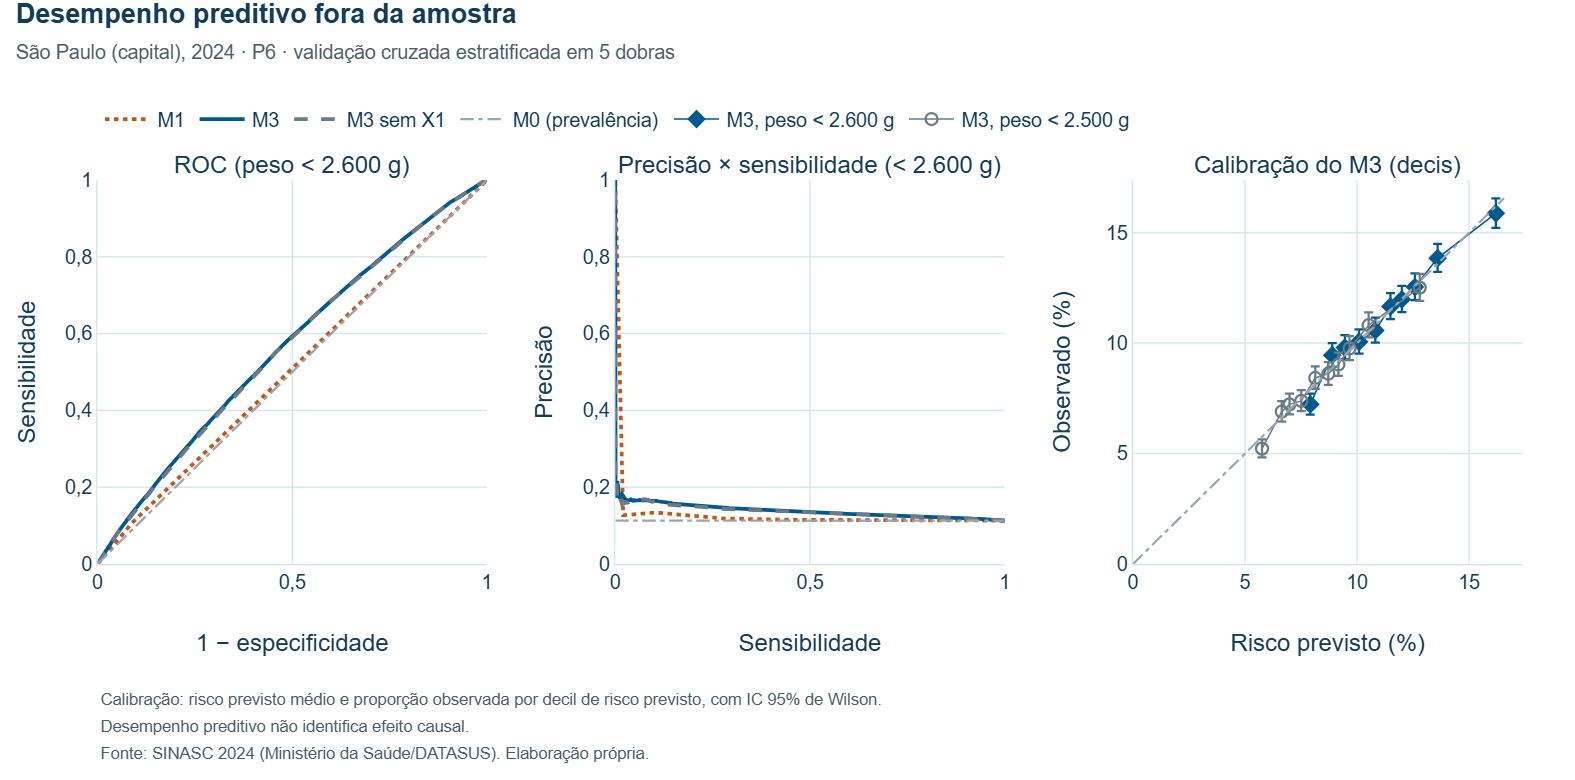

Fora da amostra, o M3 tem ROC-AUC 0,565 para < 2.600 g (0,571 para < 2.500 g): num par com um caso e um não caso, o caso recebe o risco previsto maior em 56% das vezes, contra 50% no M0; a average precision é 0,138, para uma prevalência de 0,113. Acrescentar X1 ao M3 sem X1 muda a AUC em +0,002 e o Brier em −0,00003: X1 se associa ao desfecho (seção 1), mas quase não melhora a previsão. As previsões estão próximas da calibração ideal (inclinação 0,97, ideal 1; risco médio previsto menos observado: 0,00 p.p.), e capacidade preditiva, alta ou baixa, não indica efeito causal.

In [4]:
previsoes, metricas, dobras, linhas = {}, {}, {}, []
for rotulo, desfecho in DESFECHOS.items():
    y = p6[desfecho].to_numpy()
    for nome, preditores in MODELOS.items():
        previsoes[rotulo, nome], dobras[rotulo] = prever_fora_da_amostra(construir_modelo(preditores), x_p6, y)
        m = metricas[rotulo, nome] = metricas_probabilisticas(y, previsoes[rotulo, nome])
        linhas.append({"Modelo": nome, "Desfecho": rotulo, "ROC-AUC": fmt(m["roc_auc"], 3),
                       "Average precision": fmt(m["average_precision"], 3), "Prevalência": fmt(m["prevalencia"], 3),
                       "Brier": fmt(m["brier"], 4),
                       "Previsto − observado (p.p.)": fmt(round(100 * m["dif_media_prevista_observada"], 2) + 0.0, 2),
                       "Inclinação de calibração": "—" if np.isnan(m["inclinacao_calibracao"])
                       else fmt(m["inclinacao_calibracao"], 2)})
display(pd.DataFrame(linhas).set_index("Modelo"))

def reduzir(x, y, n=200):
    i = np.unique(np.linspace(0, len(x) - 1, min(n, len(x))).astype(int))
    return x[i], y[i]

y26 = p6.Y_2600.to_numpy()
fig_prev = make_subplots(rows=1, cols=3, horizontal_spacing=0.09,
                         subplot_titles=("ROC (peso < 2.600 g)", "Precisão × sensibilidade (< 2.600 g)",
                                         "Calibração do M3 (decis)"))
for nome, cor, traco in [("M1", COR_T0, "dot"), ("M3", COR_T1, "solid"), ("M3 sem X1", COR_REFERENCIA, "dash")]:
    fpr, tpr = reduzir(*roc_curve(y26, previsoes["< 2.600 g", nome])[:2])
    fig_prev.add_scatter(x=fpr, y=tpr, mode="lines", name=nome, legendgroup=nome, row=1, col=1,
                         line=dict(color=cor, dash=traco, width=2.5),
                         hovertemplate=nome + "<br>1 − especificidade %{x:.2f}<br>sensibilidade %{y:.2f}<extra></extra>")
    precisao, sensibilidade = precision_recall_curve(y26, previsoes["< 2.600 g", nome])[:2]
    sensibilidade, precisao = reduzir(sensibilidade, precisao)
    fig_prev.add_scatter(x=sensibilidade, y=precisao, mode="lines", name=nome, legendgroup=nome, showlegend=False,
                         row=1, col=2, line=dict(color=cor, dash=traco, width=2.5),
                         hovertemplate=nome + "<br>sensibilidade %{x:.2f}<br>precisão %{y:.2f}<extra></extra>")
prevalencia = y26.mean()
for coluna, xs, ys in [(1, [0, 1], [0, 1]), (2, [0, 1], [prevalencia, prevalencia])]:
    fig_prev.add_scatter(x=xs, y=ys, mode="lines", name="M0 (prevalência)", legendgroup="M0", showlegend=coluna == 1,
                         row=1, col=coluna, line=dict(color="#9AA5AD", dash="dashdot", width=1.5), hoverinfo="skip")
limite = 0
for rotulo, cor, simbolo in [("< 2.600 g", COR_T1, "diamond"), ("< 2.500 g", COR_REFERENCIA, "circle-open")]:
    curva = curva_calibracao(p6[DESFECHOS[rotulo]].to_numpy(), previsoes[rotulo, "M3"])
    limite = max(limite, 100 * curva[["previsto", "ic95_sup"]].to_numpy().max())
    fig_prev.add_scatter(
        x=100 * curva.previsto, y=100 * curva.observado, mode="markers+lines", name=f"M3, peso {rotulo}",
        row=1, col=3, marker=dict(color=cor, symbol=simbolo, size=8, line=dict(width=1.5, color=cor)),
        line=dict(color=cor, width=1),
        error_y=dict(type="data", symmetric=False, array=100 * (curva.ic95_sup - curva.observado),
                     arrayminus=100 * (curva.observado - curva.ic95_inf), thickness=1.5, width=3, color=cor),
        hovertemplate="previsto %{x:.1f}%<br>observado %{y:.1f}%<extra>" + rotulo + "</extra>")
fig_prev.add_scatter(x=[0, limite], y=[0, limite], mode="lines", showlegend=False, row=1, col=3,
                     line=dict(color="#9AA5AD", dash="dashdot", width=1.5), hoverinfo="skip")
layout_academico(
    fig_prev, "Desempenho preditivo fora da amostra",
    "São Paulo (capital), 2024 · P6 · validação cruzada estratificada em 5 dobras",
    notas=["Calibração: risco previsto médio e proporção observada por decil de risco previsto, com IC 95% de Wilson.",
           "Desempenho preditivo não identifica efeito causal.", FONTE_SINASC_2024],
    nome_arquivo="nb06_desempenho_preditivo", altura=520)
fig_prev.update_xaxes(title="1 − especificidade", range=[0, 1], row=1, col=1)
fig_prev.update_yaxes(title="Sensibilidade", range=[0, 1], row=1, col=1)
fig_prev.update_xaxes(title="Sensibilidade", range=[0, 1], row=1, col=2)
fig_prev.update_yaxes(title="Precisão", range=[0, 1], row=1, col=2)
fig_prev.update_xaxes(title="Risco previsto (%)", range=[0, limite * 1.05], row=1, col=3)
fig_prev.update_yaxes(title="Observado (%)", range=[0, limite * 1.05], row=1, col=3)
fig_prev.update_layout(legend=dict(orientation="h", x=0, y=1.1, yanchor="bottom"), margin=dict(t=120))
exibir_plotly(fig_prev)

def com_sinal(valor, casas):
    return ("+" if valor > 0 else "−" if valor < 0 else "") + fmt(abs(valor), casas)

m26, m25, sem_x1 = metricas["< 2.600 g", "M3"], metricas["< 2.500 g", "M3"], metricas["< 2.600 g", "M3 sem X1"]
d_auc, d_brier = m26["roc_auc"] - sem_x1["roc_auc"], m26["brier"] - sem_x1["brier"]
ganho = "quase não melhora a previsão" if abs(d_auc) < 0.01 else "muda a previsão"
calibracao = ("próximas da calibração ideal" if abs(m26["inclinacao_calibracao"] - 1) < 0.1
              and abs(m26["dif_media_prevista_observada"]) < 0.0005 else "afastadas da calibração ideal")
display(Markdown(
    f"Fora da amostra, o M3 tem ROC-AUC {fmt(m26['roc_auc'], 3)} para < 2.600 g ({fmt(m25['roc_auc'], 3)} para "
    f"< 2.500 g): num par com um caso e um não caso, o caso recebe o risco previsto maior em "
    f"{fmt(100 * m26['roc_auc'], 0)}% das vezes, contra 50% no M0; a average precision é "
    f"{fmt(m26['average_precision'], 3)}, para uma prevalência de {fmt(m26['prevalencia'], 3)}. Acrescentar X1 ao M3 "
    f"sem X1 muda a AUC em {com_sinal(d_auc, 3)} e o Brier em {com_sinal(d_brier, 5)}: X1 se associa ao desfecho "
    f"(seção 1), mas {ganho}. As previsões estão {calibracao} (inclinação "
    f"{fmt(m26['inclinacao_calibracao'], 2)}, ideal 1; risco médio previsto menos observado: "
    f"{fmt(round(100 * m26['dif_media_prevista_observada'], 2) + 0.0, 2)} p.p.), e capacidade preditiva, alta ou "
    "baixa, não indica efeito causal."))

## 3. Peso ao nascer em gramas

Medidas por mês de início do pré-natal. A comparação principal (meses 1–3 × 4–6) usa a diferença de médias com IC de Welch, que não supõe variâncias iguais; os meses 1–6 entram numa ANOVA de Welch. Os meses 7–9 e os 993 registros sem mês válido (889 com MESPRENAT vazio e 104 com o código 99, "ignorado") ficam fora das comparações e aparecem só para descrever a seleção.

,n,Média (IC 95%),DP,P10,P25,Mediana,P75,P90,% < 2.500 g,% < 2.600 g
Início do pré-natal (peso em gramas),,,,,,,,,,
Meses 1–3,104.576,3.155 (3.152 a 3.158),522,2.560,2.890,3.190,3.480,3.746,"8,41","11,10"
Meses 4–6,10.118,3.131 (3.121 a 3.142),555,2.480,2.845,3.173,3.480,3.760,"10,41","13,39"
Mês 1,35.224,3.165 (3.160 a 3.170),510,2.580,2.900,3.200,3.485,3.740,"7,93","10,58"
Mês 2,54.444,3.150 (3.146 a 3.154),526,2.555,2.884,3.185,3.476,3.750,"8,52","11,27"
Mês 3,14.908,3.147 (3.138 a 3.156),535,2.530,2.875,3.180,3.490,3.759,"9,13","11,70"
Mês 4,5.366,3.146 (3.131 a 3.161),544,2.515,2.865,3.185,3.480,3.766,"9,50","12,47"
Mês 5,3.005,3.120 (3.099 a 3.140),571,2.450,2.824,3.170,3.490,3.765,"11,41","14,41"
Mês 6,1.747,3.107 (3.081 a 3.133),559,2.442,2.810,3.140,3.462,3.731,"11,45","14,48"
Meses 7–9 (só P9),1.735,3.165 (3.140 a 3.190),525,2.559,2.865,3.200,3.495,3.780,"8,65","11,53"


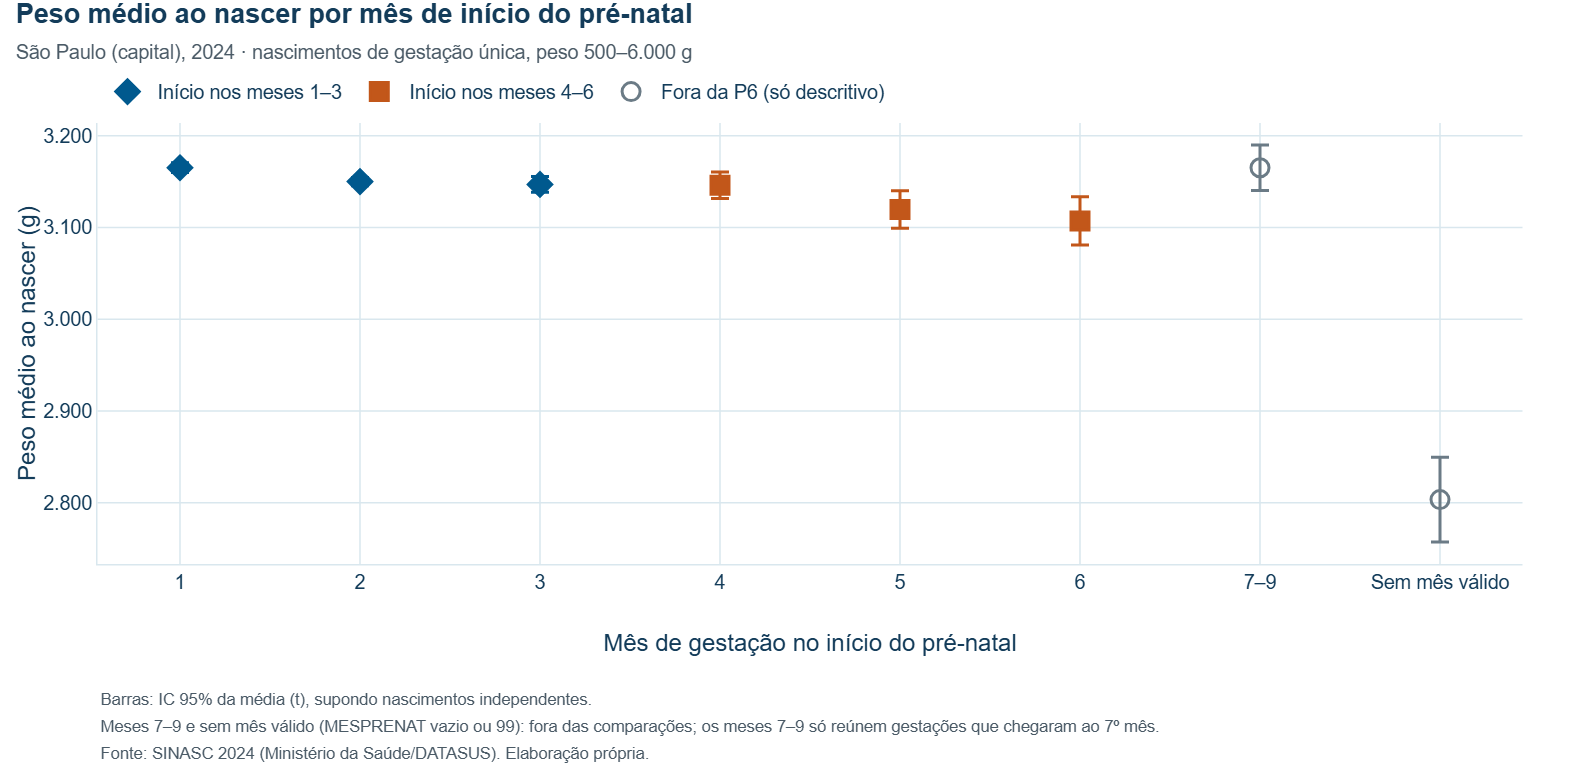

Nascidos de mães com início nos meses 1–3 pesaram em média 23 g a mais que os de início nos meses 4–6 (IC 95% de Welch: 12 a 34 g). A ANOVA de Welch dos meses 1–6 dá F(5; 10.456) = 9,3, p < 0,001, com médias mensais de 3.107 a 3.165 g; com mais de 100 mil nascimentos, o tamanho da diferença em gramas pesa mais que o valor-p. Os 993 registros sem mês de início válido (910 deles com zero consulta de pré-natal registrada) têm média de 2.804 g e 25,6% abaixo de 2.500 g, contra 8,6% na P6: excluí-los pode introduzir viés de seleção, de direção desconhecida.

In [5]:
partes = [
    (p6.peso_num, np.where(p6[X1] == 1, "Meses 1–3", "Meses 4–6")),
    (p6.peso_num, "Mês " + p6.mesprenat_num.astype(int).astype(str)),
    (p9.loc[p9.mesprenat_num >= 7, "peso_num"], "Meses 7–9 (só P9)"),
    (sem_mes.peso_num, "Sem mês válido (vazio ou 99)"),
]
resumo = pd.concat([resumir_peso(peso, pd.Series(grupo, index=peso.index)) for peso, grupo in partes])
ORDEM = ["Meses 1–3", "Meses 4–6", *(f"Mês {m}" for m in range(1, 7)), "Meses 7–9 (só P9)",
         "Sem mês válido (vazio ou 99)"]
resumo = resumo.loc[ORDEM]
display(pd.DataFrame({
    "n": resumo.n.map(fmt),
    "Média (IC 95%)": [f"{fmt(r.media)} ({fmt(r.ic95_inf)} a {fmt(r.ic95_sup)})" for r in resumo.itertuples()],
    "DP": resumo.dp.map(fmt), "P10": resumo.p10.map(fmt), "P25": resumo.p25.map(fmt),
    "Mediana": resumo.mediana.map(fmt), "P75": resumo.p75.map(fmt), "P90": resumo.p90.map(fmt),
    "% < 2.500 g": resumo.pct_menor_2500.map(lambda v: fmt(v, 2)),
    "% < 2.600 g": resumo.pct_menor_2600.map(lambda v: fmt(v, 2)),
}, index=pd.Index(ORDEM, name="Início do pré-natal (peso em gramas)")))

welch = comparar_medias_welch(p6.loc[p6[X1] == 1, "peso_num"].to_numpy(), p6.loc[p6[X1] == 0, "peso_num"].to_numpy())
anova = anova_welch({m: p6.loc[p6.mesprenat_num == m, "peso_num"].to_numpy() for m in range(1, 7)})

fig_peso = go.Figure()
for nome, rotulos, xs, cor, simbolo in [
        ("Início nos meses 1–3", ["Mês 1", "Mês 2", "Mês 3"], ["1", "2", "3"], COR_T1, "diamond"),
        ("Início nos meses 4–6", ["Mês 4", "Mês 5", "Mês 6"], ["4", "5", "6"], COR_T0, "square"),
        ("Fora da P6 (só descritivo)", ["Meses 7–9 (só P9)", "Sem mês válido (vazio ou 99)"], ["7–9", "Sem mês válido"],
         COR_REFERENCIA,
         "circle-open")]:
    r = resumo.loc[rotulos]
    fig_peso.add_scatter(
        x=xs, y=r.media, mode="markers", name=nome,
        marker=dict(color=cor, symbol=simbolo, size=12, line=dict(width=2, color=cor)),
        error_y=dict(type="data", symmetric=False, array=r.ic95_sup - r.media, arrayminus=r.media - r.ic95_inf,
                     thickness=2, width=6, color=cor),
        customdata=[[fmt(v.n), fmt(v.ic95_inf), fmt(v.ic95_sup), fmt(v.pct_menor_2500, 2)] for v in r.itertuples()],
        hovertemplate=("<b>%{x}</b><br>média %{y:.0f} g (IC 95% %{customdata[1]} a %{customdata[2]})<br>"
                       "n %{customdata[0]} · %{customdata[3]}% < 2.500 g<extra></extra>"))
layout_academico(
    fig_peso, "Peso médio ao nascer por mês de início do pré-natal",
    "São Paulo (capital), 2024 · nascimentos de gestação única, peso 500–6.000 g",
    notas=["Barras: IC 95% da média (t), supondo nascimentos independentes.",
           "Meses 7–9 e sem mês válido (MESPRENAT vazio ou 99): fora das comparações; os meses 7–9 só reúnem gestações "
           "que chegaram ao 7º mês.",
           FONTE_SINASC_2024],
    nome_arquivo="nb06_peso_por_mes", altura=520)
fig_peso.update_xaxes(title="Mês de gestação no início do pré-natal", type="category",
                      categoryorder="array", categoryarray=["1", "2", "3", "4", "5", "6", "7–9", "Sem mês válido"])
fig_peso.update_yaxes(title="Peso médio ao nascer (g)", tickformat=",.0f")
fig_peso.update_layout(legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"))
exibir_plotly(fig_peso)

def valor_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {fmt(p, 3)}"

sentido = "a mais" if welch["diferenca"] > 0 else "a menos"
medias = resumo.loc[[f"Mês {m}" for m in range(1, 7)], "media"]
ign, total = resumo.loc["Sem mês válido (vazio ou 99)"], 100 * p6.Y_2500.mean()
display(Markdown(
    f"Nascidos de mães com início nos meses 1–3 pesaram em média {fmt(abs(welch['diferenca']))} g {sentido} que os "
    f"de início nos meses 4–6 (IC 95% de Welch: {fmt(welch['ic95_inf'])} a {fmt(welch['ic95_sup'])} g). A ANOVA de "
    f"Welch dos meses 1–6 dá F({anova['gl1']}; {fmt(anova['gl2'], 0)}) = {fmt(anova['F'], 1)}, {valor_p(anova['p'])}, "
    f"com médias mensais de {fmt(medias.min())} a {fmt(medias.max())} g; com mais de 100 mil nascimentos, o tamanho "
    f"da diferença em gramas pesa mais que o valor-p. Os {fmt(ign.n)} registros sem mês de início válido "
    f"({fmt(zero_consulta)} deles com zero consulta de pré-natal registrada) têm média de {fmt(ign.media)} g e "
    f"{fmt(ign.pct_menor_2500, 1)}% abaixo de 2.500 g, contra {fmt(total, 1)}% na P6: excluí-los pode introduzir "
    "viés de seleção, de direção desconhecida."))

## Limitações

- **Previsão, associação e causa:** AUC, average precision, Brier e calibração medem previsão. A OR mede associação condicional. Nenhuma das duas afasta o confundimento não medido do 03 (renda, plano de saúde, tabagismo, acesso).
- **Temporalidade e seleção:** mês de início e covariáveis são registrados no parto. Só entram nascidos vivos com peso entre 500 e 6.000 g. Os meses 7–9 selecionam gestações mais longas. Os 993 registros sem mês válido, quase todos sem consulta registrada, ficam fora também da P9.
- **Codificação:** "sem escolaridade" agrupada com fundamental I e imputação pela moda dos 94 ignorados (seção 1). A sensibilidade por casos completos não testa outras formas de tratar a ausência.
- **Medida:** 2.600 g não é ponto de corte padrão; o da OMS é < 2.500 g.
- **Incerteza:** os IC de Wald, de Welch e da média supõem nascimentos independentes.
- **Validação:** avaliação retrospectiva, só com validação interna (validação cruzada em 2024); não é previsão clínica prospectiva nem validação externa. A validação temporal e o bootstrap das métricas ficaram para uma etapa futura.

In [6]:
# Reconciliação: confere cálculo, ausência de vazamento e reprodutibilidade; nada exige significância.
assert len(sem_mes) == 993 and (sem_codigo, codigo_99, zero_consulta) == (889, 104, 910)
assert sem_codigo + codigo_99 == len(sem_mes) and len(p9) - len(p6) == 1_735
# Números citados no texto da seção 1.
escolaridade = p6.groupby("ESCOLARIDADE_MAE").agg(n=("Y_2500", "size"), casos=("Y_2500", "sum"))
assert (escolaridade.loc["0", "n"], escolaridade.loc["0", "casos"], escolaridade.loc["1", "n"]) == (33, 2, 692)
assert len(p6_cc) == len(p6) - 94 == 114_600 and fmt(100 * p6.loc[~completos, "Y_2500"].mean(), 1) == "12,8"
# Reprodução dos valores publicados no pacote v2 (especificação principal inalterada).
assert [or_ic(ors[r, "P6"].loc[X1]) for r in DESFECHOS] == ["0,83 (0,78 a 0,88)", "0,81 (0,76 a 0,87)"]
assert [or_ic(ors[r, "P9"].loc[X1]) for r in DESFECHOS] == ["0,85 (0,80 a 0,90)", "0,84 (0,78 a 0,89)"]
assert [fmt(metricas[r, "M3"]["roc_auc"], 3) for r in DESFECHOS] == ["0,565", "0,571"]
assert (fmt(welch["diferenca"]), fmt(welch["ic95_inf"]), fmt(welch["ic95_sup"])) == ("23", "12", "34")
assert int(p6.Y_2600.sum() - p6.Y_2500.sum()) == int(p6.peso_num.between(2500, 2599).sum())
assert sum(int(p6[c].eq("IGNORADO").sum()) for c in ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PERDAS_FETAIS_CAT"]) == 94
assert list(x_p6.columns) == list(PREDITORES_M3) and list(x_p9.columns) == list(PREDITORES_M3)
for chave, diag in diagnosticos.items():
    assert diag["gradiente_max"] < 1e-8 and np.isfinite(diag["condicao"]), chave
for chave, t in ors.items():
    assert np.isfinite(t.to_numpy()).all() and ((t.ic95_inf < t["or"]) & (t["or"] < t.ic95_sup)).all(), chave
for rotulo, v in bruta.items():
    assert abs(v["or_modelo"] / v["or_tabela"] - 1) < 1e-8 and abs(v["ep_modelo"] / v["ep_tabela"] - 1) < 1e-8, rotulo
for (rotulo, nome), p in previsoes.items():
    assert len(p) == len(p6) and np.isfinite(p).all() and ((p > 0) & (p < 1)).all(), (rotulo, nome)
for rotulo, dobra in dobras.items():
    assert sorted(np.unique(dobra)) == list(range(5)) and np.bincount(dobra).min() > len(p6) // 5 - 2, rotulo
for (rotulo, nome), m in metricas.items():
    assert 0 <= m["roc_auc"] <= 1 and 0 <= m["average_precision"] <= 1 and 0 <= m["brier"] <= 1, (rotulo, nome)
    # M0 prevê a prevalência de cada dobra de treino: AUC perto de 0,5 e inclinação indefinida.
    assert nome != "M0" or (abs(m["roc_auc"] - 0.5) < 0.01 and np.isnan(m["inclinacao_calibracao"]))
repetida, _ = prever_fora_da_amostra(construir_modelo(MODELOS["M3"]), x_p6, p6.Y_2600.to_numpy())
assert np.array_equal(repetida, previsoes["< 2.600 g", "M3"])
assert welch["ic95_inf"] < welch["diferenca"] < welch["ic95_sup"] and welch["n_a"] + welch["n_b"] == len(p6)
assert anova["gl1"] == 5 and anova["gl2"] > 0 and 0 <= anova["p"] <= 1
assert int(resumo.loc[[f"Mês {m}" for m in range(1, 7)], "n"].sum()) == len(p6)
assert int(resumo.loc["Meses 1–3", "n"]) == ESPERADO_P6["x1"]
assert int(resumo.loc["Sem mês válido (vazio ou 99)", "n"]) == 993
print("Verificações do notebook 06 concluídas: populações iguais às do 03, preditores permitidos, ajustes no máximo "
      "de verossimilhança, OR bruta igual à da tabela 2×2, previsões fora da amostra completas e reprodutíveis, "
      "intervalos coerentes.")

Verificações do notebook 06 concluídas: populações iguais às do 03, preditores permitidos, ajustes no máximo de verossimilhança, OR bruta igual à da tabela 2×2, previsões fora da amostra completas e reprodutíveis, intervalos coerentes.
